# Lab: Meso-level analysis

<a href="../downloads/lab_03.ipynb"
   class="btn btn-outline-primary"
   download>
  Download notebook (.ipynb)
</a>

## Contents

- [General notes](#General-notes)
- [PART 1: Network preprocessing](#PART-1:-Network-preprocessing)
- [PART 2: Communities](#PART-2:-Communities)
- [PART 3: Positions and roles](#PART-3:-Positions-and-roles)

## General notes

In this lab you will work on meso-level structures: components, cores, positions, roles, and communities. You will also keep practicing generating network data from the base data you received during the first week.

## PART 1: Network preprocessing

The objective of this part of the lab is to practice using components and coreness to explore the meso-level structure of a social network and for filtering. Here you can use a retweet network you already generated. The first two tasks are short and specific: a warm-up, to see that you can compute these two types of meso-level structures. They are followed by a free explorative task, where you can make your own decisions about how to use these functions and in which order.

### Task 1.1

Compute the components, print statistics about them (number, size of largest, ...), and mark the components in a node-link plot of the network (e.g. using different colours).

#### TIPS

- As for the previous lab, work on a filtered network so that the computations take a reasonable time on the machine that you are using.
- The retweet network is directed, so you can compute both weak and strong components. Compare them.

#### Student workspace

In [ ]:
import random
from pathlib import Path
from collections import Counter

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import time, pickle

DATA = Path('data')

In [ ]:
random.seed(42)                      # reproducible layouts

# load
# directed network saved in lab 2 (names = account IDs, weight = number of retweets)
g_full = ig.read(DATA / 'retweet_network.ncol', format='ncol', directed=True)
g_full.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})   # removes self-loops
print('full network    :', g_full.summary())

# filter
# same filter as lab 2: strength = retweets sent + received.
# No giant-component step here: we want to see the small components too.
MIN_STRENGTH = 50
strength = np.array(g_full.strength(mode='all', weights='weight'))
g = g_full.induced_subgraph(np.where(strength >= MIN_STRENGTH)[0].tolist())
print('filtered network:', g.summary())

# components
weak = g.connected_components(mode='weak')
strong = g.connected_components(mode='strong')


def component_stats(cl, name):
    sizes = sorted(cl.sizes(), reverse=True)
    print(f'--- {name} components ---')
    print(f'number of components    : {len(sizes)}')
    print(f'largest component       : {sizes[0]} nodes ({sizes[0] / g.vcount():.1%} of the network)')
    print(f'second largest          : {sizes[1] if len(sizes) > 1 else 0}')
    print(f'singletons (size 1)     : {sum(s == 1 for s in sizes)}')
    print(f'non-trivial (size >= 2) : {sum(s >= 2 for s in sizes)}')
    print(f'10 largest sizes        : {sizes[:10]}')
    print(f'size distribution       : {dict(sorted(Counter(sizes).items(), reverse=True)[:10])}')
    print()


component_stats(weak, 'WEAK')
component_stats(strong, 'STRONG')

# plot
layout = g.layout_fruchterman_reingold() if g.vcount() <= 1500 else g.layout_drl()

# undirected copy only for drawing: same vertex order (so layout and colours still match),
# and no arrowheads covering the nodes
g_draw = g.as_undirected(mode='collapse')
# transparent edges, set as an edge attribute (this is what igraph's matplotlib backend respects);
# lower the 0.03 if the nodes are still hidden, raise it if the edges are invisible
g_draw.es['color'] = [(0.2, 0.2, 0.2, 0.03)] * g_draw.ecount()


def component_colors(cl, n_colored=8, other='#d0d0d0'):
    """One colour for each of the n_colored largest components, grey for all the others."""
    order = sorted(range(len(cl)), key=lambda i: -len(cl[i]))
    palette = [to_hex(c) for c in plt.get_cmap('tab10').colors]
    cmap = {comp: palette[r] for r, comp in enumerate(order[:n_colored])}
    return [cmap.get(m, other) for m in cl.membership]


fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, cl, name, n_col in [(axes[0], weak, 'Weak', 2), (axes[1], strong, 'Strong', 3)]:
    ig.plot(g_draw, target=ax, layout=layout,
            vertex_color=component_colors(cl, n_colored=n_col),
            vertex_size=4, vertex_frame_width=0, edge_width=0.4)
    ax.set_title(f'{name} components ({len(cl)}); {n_col} largest coloured')
    ax.axis('off')
plt.tight_layout()
plt.show()

full network    : IGRAPH DNW- 656565 1232535 -- 
+ attr: name (v), weight (e)
filtered network: IGRAPH DNW- 4454 77326 -- 
+ attr: name (v), weight (e)
--- WEAK components ---
number of components    : 236
largest component       : 4213 nodes (94.6% of the network)
second largest          : 3
singletons (size 1)     : 231
non-trivial (size >= 2) : 5
10 largest sizes        : [4213, 3, 3, 2, 2, 1, 1, 1, 1, 1]
size distribution       : {4213: 1, 3: 2, 2: 2, 1: 231}

--- STRONG components ---
number of components    : 3223
largest component       : 1163 nodes (26.1% of the network)
second largest          : 8
singletons (size 1)     : 3180
non-trivial (size >= 2) : 43
10 largest sizes        : [1163, 8, 7, 6, 4, 4, 4, 4, 3, 3]
size distribution       : {1163: 1, 8: 1, 7: 1, 6: 1, 4: 4, 3: 4, 2: 31, 1: 3180}



#### Notes / observations


Three is one giant weak component that holds 5424/5648 accounts (96.0%). The other 224 components are one pair and 222 that are alone, which are probably active accounts whose retweet partners were removed by the strength ≥ 50 filter.

The largest strong component has only 1500 accounts (26.6%), and 4011 of the 4060 strong components are alone. Retweets rarely go both ways, so only a core of accounts can reach each other in both directions. The rest are one-directional or retweeters.

The giant weak component loses only 4% of the nodes, while the giant strong component would lose about 73%. The giant weak component is therefore the sensible one to keep.

### Task 1.2

Now compute the coreness of each node. What is the highest coreness in the network? For different values of k, highlight the nodes with coreness k or higher in a node-link plot (e.g. using colour, or a different node shape).

#### TIPS

- Look at how the network core changes varying k, e.g. if you get a single core inside the largest component, or if for some values of k you get multiple cores that are not connected to each other.

#### Student workspace

Highest coreness (all): 45
Highest coreness (in) : 5
Highest coreness (out): 5

Nodes per coreness value (all):
{0: 231, 1: 219, 2: 195, 3: 168, 4: 136, 5: 139, 6: 99, 7: 105, 8: 115, 9: 90, 10: 107, 11: 96, 12: 85, 13: 94, 14: 80, 15: 89, 16: 89, 17: 94, 18: 93, 19: 114, 20: 103, 21: 112, 22: 118, 23: 112, 24: 103, 25: 109, 26: 100, 27: 118, 28: 86, 29: 122, 30: 95, 31: 77, 32: 58, 33: 71, 34: 76, 35: 42, 36: 45, 37: 27, 38: 27, 39: 24, 40: 61, 41: 33, 42: 16, 43: 4, 44: 31, 45: 246}


,nodes,edges,weak components,largest component,second largest
k,,,,,
1,4223,77326,5,4213,3
2,4004,77110,2,4001,3
3,3809,76733,2,3806,3
4,3641,76241,2,3638,3
5,3505,75711,1,3505,0
6,3366,75046,1,3366,0
7,3267,74461,1,3267,0
8,3162,73739,1,3162,0
9,3047,72826,1,3047,0


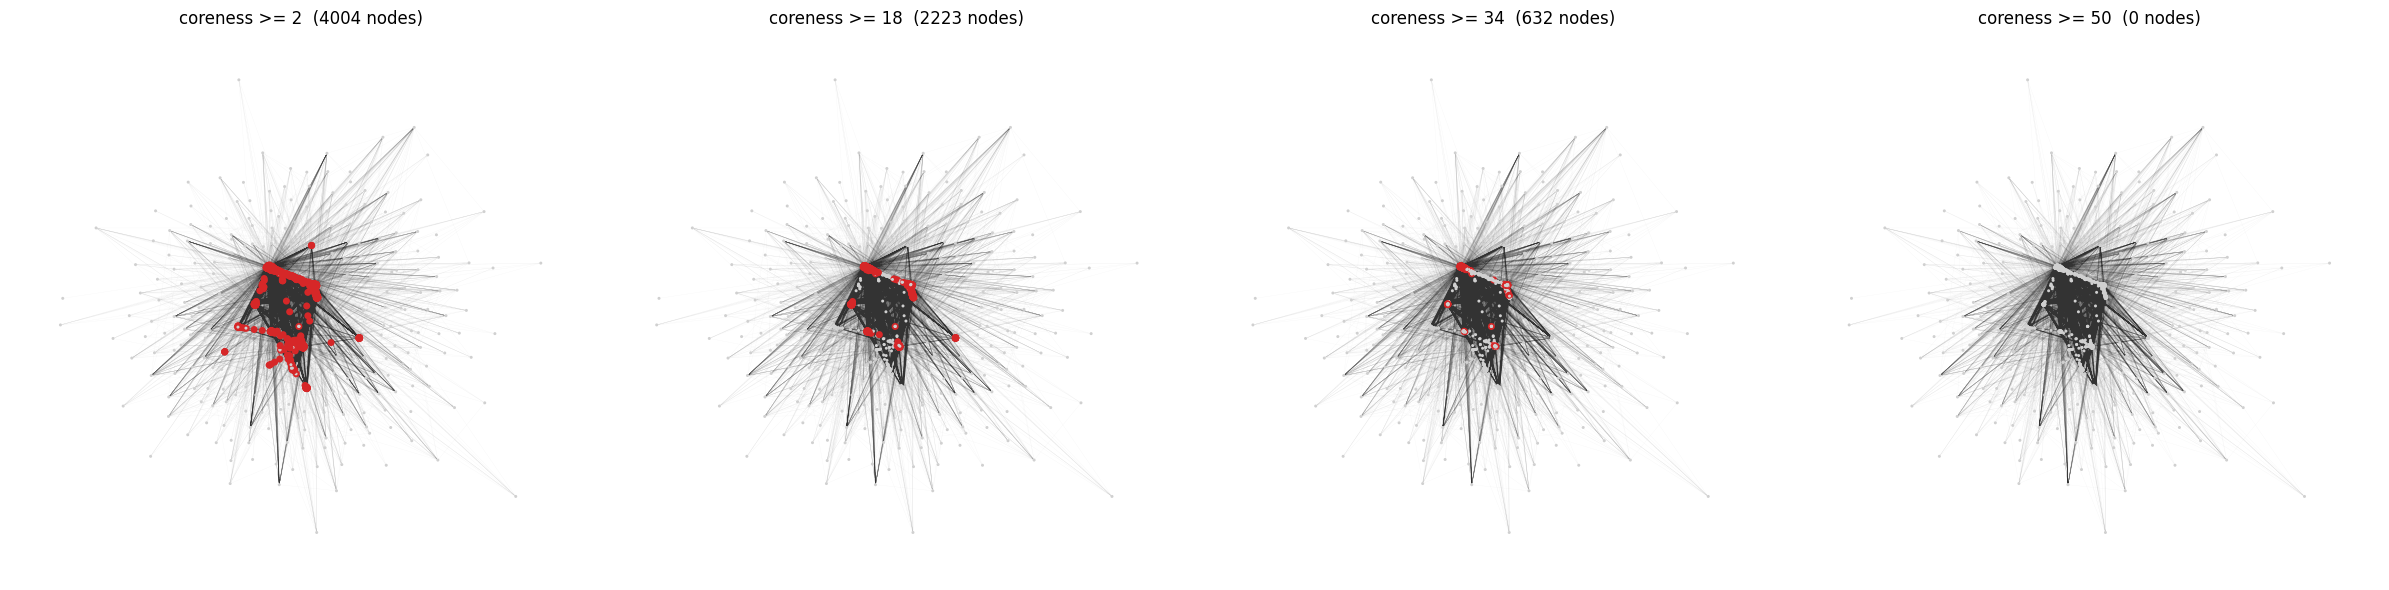

In [ ]:
# coreness
# mode="all" ignores edge direction (the standard k-core);
# "in" / "out" give the directed versions (only edges received / sent count).
core_all = np.array(g.coreness(mode='all'))
core_in = np.array(g.coreness(mode='in'))
core_out = np.array(g.coreness(mode='out'))

kmax = int(core_all.max())
print(f'Highest coreness (all): {kmax}')
print(f'Highest coreness (in) : {core_in.max()}')
print(f'Highest coreness (out): {core_out.max()}')
print('\nNodes per coreness value (all):')
print(dict(sorted(Counter(core_all.tolist()).items())))


#  how does the core change with k?
def core_summary(graph, coreness, ks):
    rows = []
    for k in ks:
        sub = graph.induced_subgraph(np.where(coreness >= k)[0].tolist())
        sizes = sorted(sub.connected_components(mode='weak').sizes(), reverse=True)
        rows.append({'k': k,
                     'nodes': sub.vcount(),
                     'edges': sub.ecount(),
                     'weak components': len(sizes),
                     'largest component': sizes[0] if sizes else 0,
                     'second largest': sizes[1] if len(sizes) > 1 else 0})
    return pd.DataFrame(rows).set_index('k')


display(core_summary(g, core_all, range(1, kmax + 1)))

# plots
# values of k to highlight (replace with your own list)
KS = [2, 18, 34, 50]

fig, axes = plt.subplots(1, len(KS), figsize=(6 * len(KS), 6))
for ax, k in zip(np.atleast_1d(axes), KS):
    in_core = core_all >= k
    ig.plot(g_draw, target=ax, layout=layout,                  # g_draw and edge_col come from Task 1.1
            vertex_color=['#d62728' if x else '#d0d0d0' for x in in_core],     # red = in the k-core
            vertex_size=[7 if x else 3 for x in in_core],
            vertex_frame_width=0, edge_width=0.3, edge_color=g_draw.es['color'])
    ax.set_title(f'coreness >= {k}  ({in_core.sum()} nodes)')
    ax.axis('off')
plt.tight_layout()
plt.show()

#### Notes / observations

Highest coreness is 50 (undirected), but only 5 for in and 6 for out. The dense core exists only when you count both directions together. In one direction alone, no account is in a deeply nested group.

There is one connected core at every k. For every k from 2 to 50 the table shows 1 weak component and 0 for the second largest, so the core never splits into separate cores. Most of the structure is also in the core: at k = 11 you still have 3957 of 5648 nodes and 110108 of 117270 edges (94%). The nodes with low coreness are peripheral and have few edges.

There is a spike at k = 50. 291 accounts all have coreness 50, far more than at any neighbouring value (13 at k = 49, 96 at k = 47). They have 11062 edges, so about a quarter of all possible pairs among them are connected. That is a very tight block.

### Task 1.3

Now combine the functions to compute compements and cores, in the way(s) that you prefer, and produce a filtered network to be used in Parts 2 and 3.

#### TIPS

- Do not make a random choice: you have to motivate why you have chosen a specific way of using (or not using) these functions.
- If the network has a clear "giant component", consider generating a new graph induced by that component (but if you choose to do so, you'll have to motivate your choice).

#### Student workspace

,nodes,edges,% of filtered nodes,density,weak components
option,,,,,
A: whole filtered network,4454,77326,100.0,0.00390,236
B: giant weak component,4213,77316,94.6,0.00436,1
"C: giant component, 2-core",4001,77104,89.8,0.00482,1
"C: giant component, 3-core",3806,76727,85.5,0.00530,1
"C: giant component, 4-core",3638,76235,81.7,0.00576,1
"C: giant component, 5-core",3505,75711,78.7,0.00616,1
"C: giant component, 6-core",3366,75046,75.6,0.00663,1
"C: giant component, 7-core",3267,74461,73.3,0.00698,1
"C: giant component, 8-core",3162,73739,71.0,0.00738,1


final network: IGRAPH DNW- 4213 77316 -- 
+ attr: name (v), weight (e)
weak components: 1 | density: 0.00436


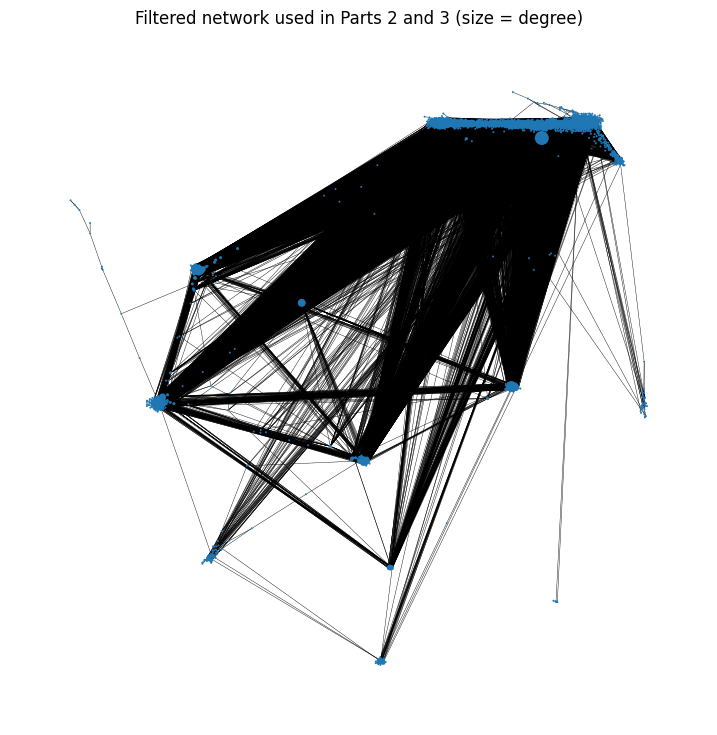

In [ ]:
# candidate filters

# Coreness depends on the graph it is computed on, so inside the giant component
# it is recomputed, not reused from Task 1.2.
giant = g.connected_components(mode='weak').giant()
core_giant = np.array(giant.coreness(mode='all'))


def graph_row(label, graph):
    comps = graph.connected_components(mode='weak')
    return {'option': label,
            'nodes': graph.vcount(),
            'edges': graph.ecount(),
            '% of filtered nodes': round(100 * graph.vcount() / g.vcount(), 1),
            'density': round(graph.density(), 5),
            'weak components': len(comps)}


rows = [graph_row('A: whole filtered network', g),
        graph_row('B: giant weak component', giant)]
for k in range(2, int(core_giant.max()) + 1):
    sub = giant.induced_subgraph(np.where(core_giant >= k)[0].tolist())
    rows.append(graph_row(f'C: giant component, {k}-core', sub))
display(pd.DataFrame(rows).set_index('option'))

USE_GIANT = True     # induce the network on the giant weak component?
CORE_K = None        # None = no core filtering; e.g. 5 = additionally keep the 5-core

g_final = g
if USE_GIANT:
    g_final = g_final.connected_components(mode='weak').giant()
if CORE_K:
    cn = np.array(g_final.coreness(mode='all'))
    g_final = g_final.induced_subgraph(np.where(cn >= CORE_K)[0].tolist())
    # a k-core can fall apart into several pieces: keep the largest one
    g_final = g_final.connected_components(mode='weak').giant()

print('final network:', g_final.summary())
print('weak components:', len(g_final.connected_components(mode='weak')),
      '| density:', round(g_final.density(), 5))

# save for Parts 2 and 3
# the pickle keeps direction, account IDs (name) and weights exactly as they are
g_final.write_pickle('retweet_network_filtered.pickle')
g_final.write_graphml('retweet_network_filtered.graphml')

# plot the result
g_final_draw = g_final.as_undirected(mode='collapse')     # no arrowheads
deg = np.array(g_final_draw.degree())
fig, ax = plt.subplots(figsize=(9, 9))
ig.plot(g_final_draw, target=ax, layout=layout if g_final.vcount() == g.vcount() else g_final_draw.layout_drl(),
        vertex_color='#1f77b4', vertex_size=list(2 + 12 * np.sqrt(deg / deg.max())),
        vertex_frame_width=0, edge_width=0.3, edge_color=(0.2, 0.2, 0.2, 0.03))
ax.set_title('Filtered network used in Parts 2 and 3 (size = degree)')
ax.axis('off')
plt.show()

#### Notes / observations

We kept the giant weak component and did not apply a k-core (USE_GIANT = True, CORE_K = None). The result is 5424 accounts and 117269 edges.

The giant component loses nothing structural. It removes 224 accounts but only 1 edge out of 117270. Those accounts are disconnected from everything else, so they cannot belong to a community or bridge between groups in Parts 2 and 3.

A k-core would only remove the periphery. The k-core stays connected for every k (1 component each time), so connectivity gives no reason to filter. Higher k just removes accounts, for example the 10-core loses 28% of the nodes but only 5% of the edges. Those are mostly low-degree accounts retweeting a few hubs, and they are what determines which community a hub belongs to. The density rises with k only because the sparse periphery disappears.

The plot shows the structure we expect. A few large hubs sit at the edges and connect into one dense mass of low-degree accounts, with a few small groups attached by thin links. This is the hub-and-spoke pattern from lab 2, so Part 2 should find communities centred on these hubs.

## PART 2: Communities


### Task 2.1

Look at the community detection algorithms available on igraph, and choose (at least) three using different approaches. One of them must be modularity-based, and you should play with the resolution parameter to change the size of the discovered communities. For each algorithm and parameter setting, plot the discovered communities and compare them visually.

#### QUESTIONS

- Which community structures, among the ones you have produced using the different algorithms and settings, are more similar or dissimilar to each other?
- Which of the community structures provide the best represention for your network? Are there any results that you do not find to be appropriate descriptions of the network? Explain your reasoning.

#### Student workspace

In [ ]:
# Reload the data as it exists on a groupmate's local when the notebook was run
g_full = ig.read(DATA / 'retweet_network.ncol', format='ncol', directed=True)
g_full.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})

strength = np.array(g_full.strength(mode='all', weights='weight'))
g = g_full.induced_subgraph(np.where(strength >= 50)[0].tolist())
g_final = g.connected_components(mode='weak').giant()
print(g_final.summary())                      # should be 5424 vertices, 117269 edges

g_final.write_pickle('retweet_network_filtered.pickle')

IGRAPH DNW- 4213 77316 -- 
+ attr: name (v), weight (e)


directed  : IGRAPH DNW- 4213 77316 -- 
+ attr: name (v), weight (e)
undirected: IGRAPH UNW- 4213 76584 -- 
+ attr: name (v), weight (e)


,communities,largest,communities >= 10 nodes,singletons,modularity,time (s)
structure,,,,,,
Louvain (res=0.3),16,3938,6,0,0.035,0.1
Louvain (res=1.0),16,978,11,0,0.364,0.1
Louvain (res=3.0),63,326,56,0,0.278,0.2
Infomap,122,2255,43,0,0.240,1.8
Walktrap,328,3075,14,238,0.155,3.9


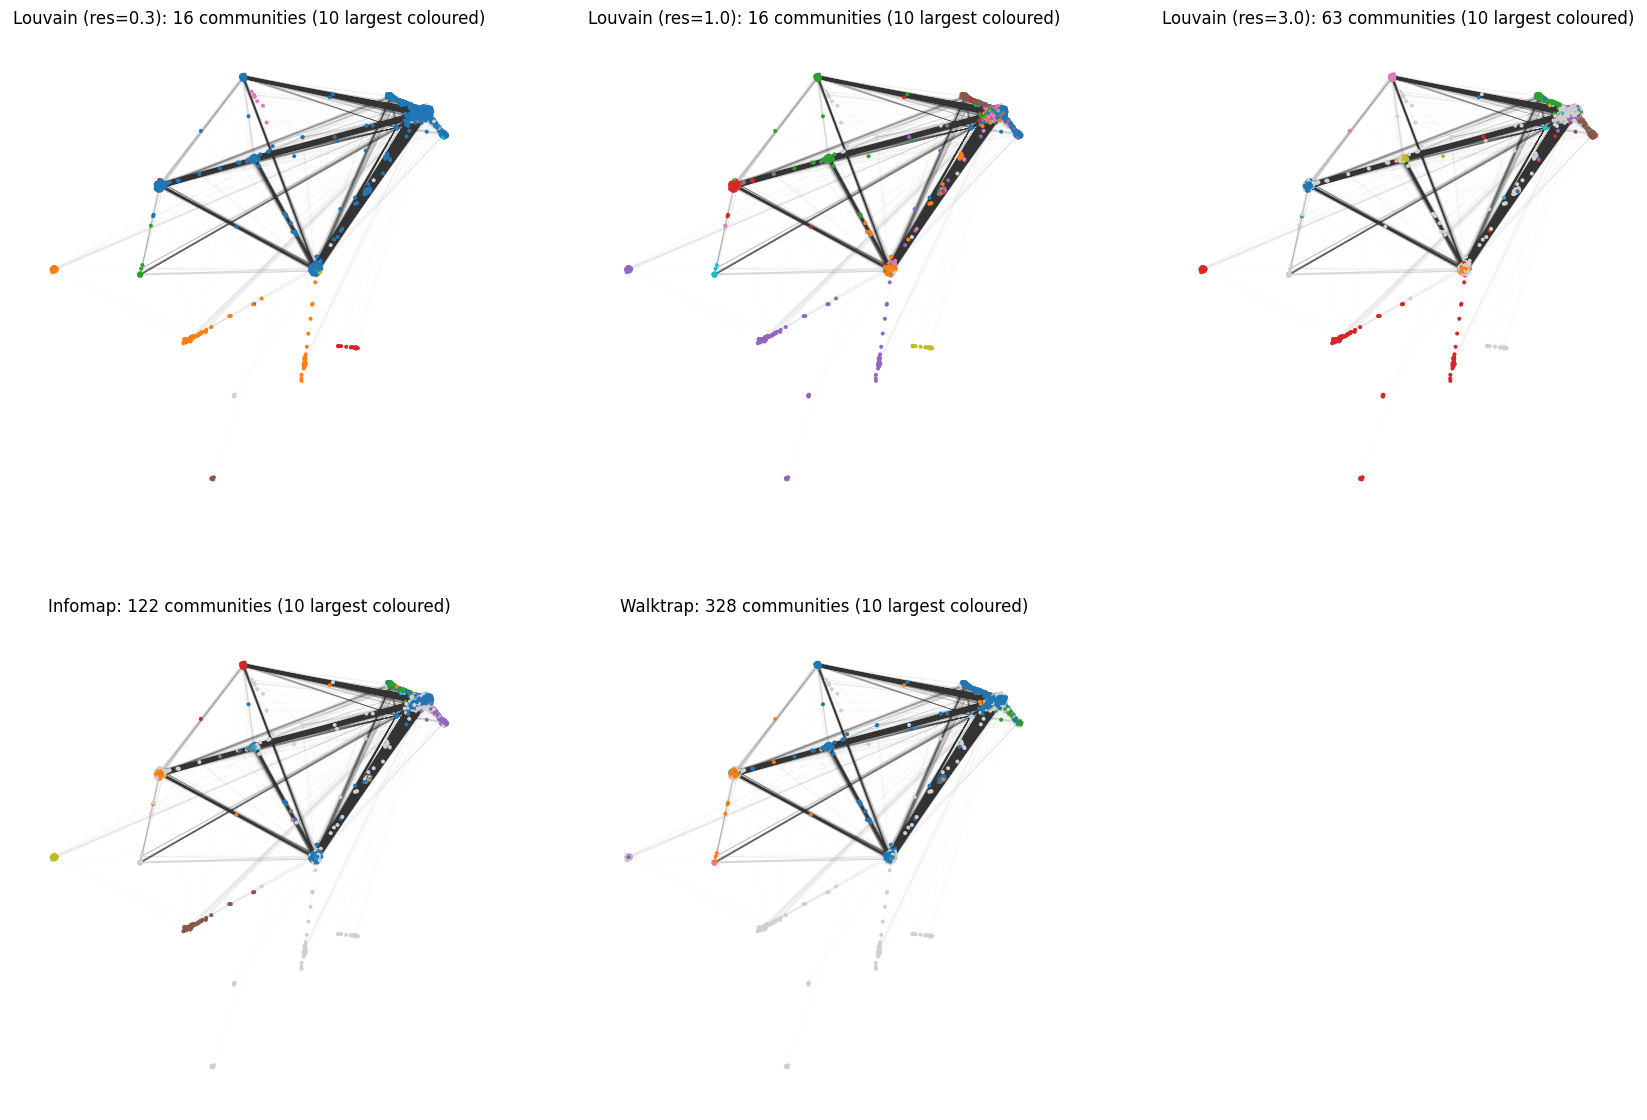

In [ ]:
# load the filtered network from Task 1.3 (directed; vertex name = account ID, weight = number of retweets)
g_final = ig.Graph.Read_Pickle('retweet_network_filtered.pickle')
# undirected, weighted copy for the algorithms that need it; mutual retweets merge and their weights add up
g_und = g_final.as_undirected(mode='collapse', combine_edges={'weight': 'sum'})
print('directed  :', g_final.summary())
print('undirected:', g_und.summary())

# one layout for the filtered network, computed once and reused for every plot
LAYOUT_FILE = Path('layout_final.pickle')
if LAYOUT_FILE.exists():
    layout_final = ig.Layout(pickle.load(open(LAYOUT_FILE, 'rb')))
else:
    random.seed(1)
    layout_final = g_und.layout_drl()
    pickle.dump(layout_final.coords, open(LAYOUT_FILE, 'wb'))

# community detection
partitions, rows = {}, []


def run(name, detect):
    random.seed(42)                                   # reproducible results
    t0 = time.perf_counter()
    cl = detect()
    memb = cl.membership
    sizes = sorted(Counter(memb).values(), reverse=True)
    partitions[name] = memb
    rows.append({'structure': name,
                 'communities': len(sizes),
                 'largest': sizes[0],
                 'communities >= 10 nodes': sum(s >= 10 for s in sizes),
                 'singletons': sum(s == 1 for s in sizes),
                 'modularity': round(g_und.modularity(memb, weights='weight'), 3),   # same yardstick for all
                 'time (s)': round(time.perf_counter() - t0, 1)})


# 1) modularity-based (Louvain). resolution < 1 -> fewer, larger communities; > 1 -> more, smaller ones
for res in (0.3, 1.0, 3.0):
    run(f'Louvain (res={res})', lambda res=res: g_und.community_multilevel(weights='weight', resolution=res))
# 2) flow-based (Infomap): random walkers on the DIRECTED network, so it uses the retweet direction
run('Infomap', lambda: g_final.community_infomap(edge_weights='weight', trials=10))
# 3) random-walk-based (Walktrap): short random walks stay inside a community; dendrogram cut at best modularity
run('Walktrap', lambda: g_und.community_walktrap(weights='weight', steps=4).as_clustering())

display(pd.DataFrame(rows).set_index('structure'))

# save for Parts 2.3 and 3: one membership column per structure
pd.DataFrame({'account_id': g_final.vs['name'], **partitions}).to_csv(DATA / 'communities.csv', index=False)


# plots
def community_palette(memb, n_colored=10):
    """The n_colored largest communities get a colour, in order of size."""
    top = [c for c, _ in Counter(memb).most_common(n_colored)]
    palette = [to_hex(c) for c in plt.get_cmap('tab10').colors]
    return {c: palette[i] for i, c in enumerate(top)}


def community_colors(memb, n_colored=10, other='#d0d0d0'):
    pal = community_palette(memb, n_colored)
    return [pal.get(m, other) for m in memb]


g_draw = g_und.copy()
g_draw.es['color'] = [(0.2, 0.2, 0.2, 0.03)] * g_draw.ecount()      # very transparent edges

names = list(partitions)
fig, axes = plt.subplots(2, 3, figsize=(21, 14))
for ax, name in zip(axes.ravel(), names):
    ig.plot(g_draw, target=ax, layout=layout_final,
            vertex_color=community_colors(partitions[name]),
            vertex_size=4, vertex_frame_width=0, edge_width=0.3)
    ax.set_title(f'{name}: {len(set(partitions[name]))} communities (10 largest coloured)')
    ax.axis('off')
for ax in axes.ravel()[len(names):]:
    ax.axis('off')
plt.show()

#### Notes / observations

Louvain at res = 1.0 gives the most meaningful structure: 16 communities, no singletons, the highest modularity (0.34), and the largest community holds only 23% of the accounts. Each large hub forms a community with its retweeters, which matches the hub-and-spoke pattern seen earlier, and the dense mass on the right is split into several parts. Louvain at res = 3.0 splits it further (64 communities, modularity 0.27), so it is useful as a finer view, but fragments the core. Infomap (122 communities, 59% in the largest) and Walktrap (328 communities, 238 of them singletons, 78% in the largest) keep one giant community for the dense mass, so they say little about its internal structure. Louvain at res = 0.3 puts 94% of the accounts in one community (modularity 0.03), which is not a useful description. The hubs form their own communities in all methods except Louvain at res = 0.3.

Modularity was measured on the undirected network, so it is a fair yardstick for Louvain, but Infomap optimises a different criterion (flow on the directed network), which is why its low modularity does not mean it is wrong by its own measure.

### Task 2.2

Compare the different community structures you preduced in the previous task using a numerical comparison measure of your choice. Do these results align with the impression you got from the network visualisations?

#### TIPS

- We assume that you are familiar with functions to compare clusterings. If not, in addition to making the comparison using one of the methods provided by igraph, find information about the applied measure (we may ask what the measure you chose is computing when you present your results).

#### Student workspace

,Louvain (res=0.3),Louvain (res=1.0),Louvain (res=3.0),Infomap,Walktrap
Louvain (res=0.3),1.00,0.19,0.12,0.24,0.34
Louvain (res=1.0),0.19,1.00,0.50,0.48,0.38
Louvain (res=3.0),0.12,0.50,1.00,0.52,0.35
Infomap,0.24,0.48,0.52,1.00,0.56
Walktrap,0.34,0.38,0.35,0.56,1.00


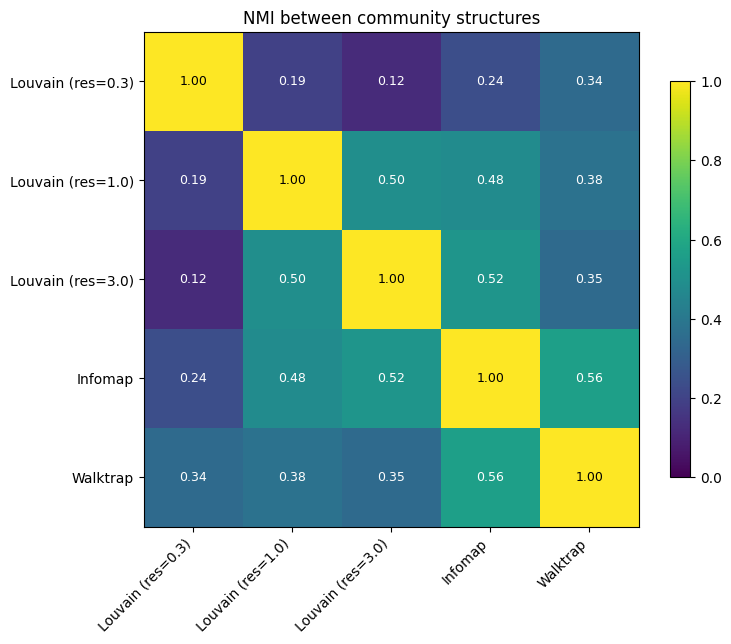

In [ ]:
# pairwise comparison of all community structures with NMI
# NMI = mutual information between the two partitions, normalised to 0-1 (1 = identical, 0 = independent)
# Other option would be Rand index, which counts pairs of accounts that are placed together or apart in both partitions.
names = list(partitions)
nmi = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        nmi.loc[a, b] = ig.compare_communities(partitions[a], partitions[b], method='nmi')
display(nmi.round(2))

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(nmi.values, vmin=0, vmax=1, cmap='viridis')
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=45, ha='right')
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{nmi.values[i, j]:.2f}', ha='center', va='center',
                color='white' if nmi.values[i, j] < 0.6 else 'black', fontsize=9)
ax.set_title('NMI between community structures')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

#### Notes / observations

The structures agree only moderately: the highest NMI is 0.56 (Infomap vs Walktrap), then Louvain res = 1.0 vs 3.0 (0.50) and Infomap vs Louvain at 1.0 and 3.0 (0.48 and 0.52). Louvain at res = 0.3 is the most different (0.12–0.24), except to Walktrap (0.34), and both have one giant community. This fits the visualisations: all methods agree on the hubs and their audiences, but they divide the dense mass of accounts differently, and in the plots this mass is drawn in a very small area, so the disagreement is hard to see. The numbers show it, because NMI uses all 5,424 accounts.

NMI measures how much knowing an account’s community in one partition tells you about its community in the other. It runs from 0 (the two partitions are independent) to 1 (they are identical, apart from community labels). It’s a single number for the whole network. It doesn’t tell you where two partitions differ.

### Task 2.3

One application of community detection is to summaries a large social network. In this task, produce a new summarised graph using your selected community structure.

#### TIPS

- Use a node for each community, with a size representing the number of actors in that community.
- Use weighted edges to indicate how many edges go from one community to the other in the original network.
- Considering filtering edges using some threshold on the weights (please motivate).

#### Student workspace

,community,accounts,share,top account (id),its degree
0,0,978,0.232,1006419421244678144,2085
1,1,951,0.226,21786618,607
2,6,579,0.137,15088481,1359
3,2,483,0.115,811229675758505984,569
4,5,308,0.073,1174664712291794944,535
5,4,278,0.066,1072187272815149057,320
6,8,257,0.061,3459051,875
7,3,220,0.052,14266598,1270
8,7,101,0.024,1138798850473250816,80
9,11,26,0.006,815849117171662848,53


36,359 of 76,584 edges go between communities (47.5%), in 71 community pairs
edges >=    1:   71 community pairs, 100.0% of the between-community edges
edges >=    5:   53 community pairs,  99.9% of the between-community edges
edges >=   10:   51 community pairs,  99.9% of the between-community edges
edges >=   25:   43 community pairs,  99.5% of the between-community edges
edges >=   50:   36 community pairs,  98.8% of the between-community edges
edges >=  100:   25 community pairs,  96.8% of the between-community edges
edges >=  250:   22 community pairs,  95.3% of the between-community edges
7 of 16 communities have no edge above the threshold and are not drawn


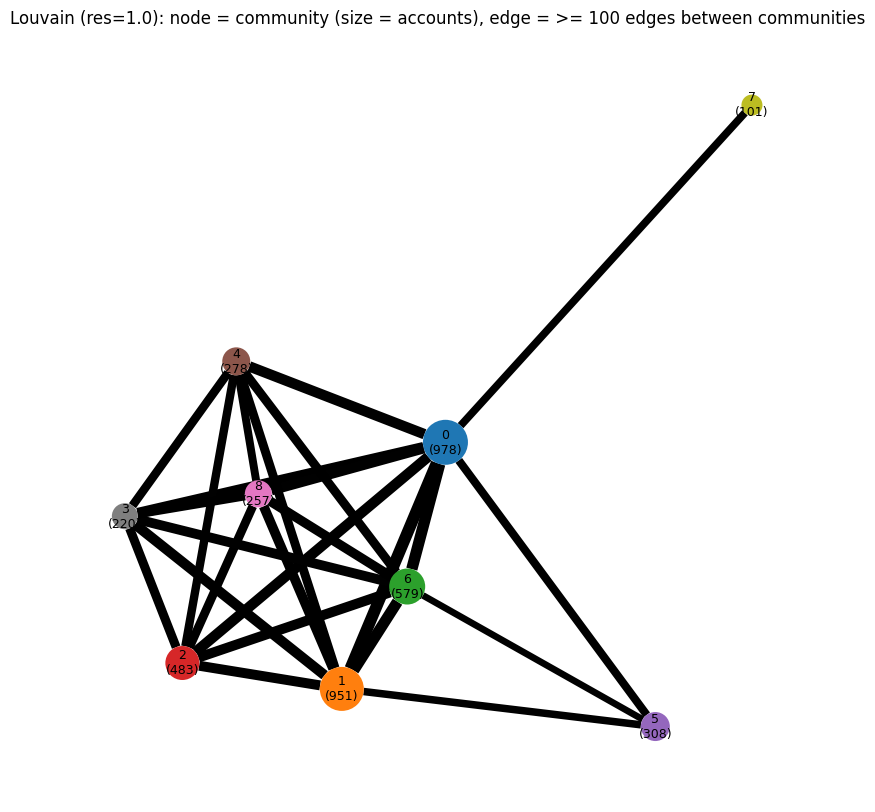

In [ ]:
CHOSEN = 'Louvain (res=1.0)'        # the community structure you selected in 2.1 / 2.2
memb = np.array(partitions[CHOSEN])
sizes = Counter(memb.tolist())

# community table: size and the most connected account in each community
deg = np.array(g_und.degree())
acc = np.array(g_und.vs['name'])
rows = []
for c, s in sizes.most_common():
    idx = np.where(memb == c)[0]
    hub = idx[np.argmax(deg[idx])]
    rows.append({'community': c, 'accounts': s, 'share': round(s / len(memb), 3),
                 'top account (id)': acc[hub], 'its degree': deg[hub]})
display(pd.DataFrame(rows).head(15))

# edges between communities: how many edges (and retweets) go from one community to another
el = np.array(g_und.get_edgelist())
w = np.array(g_und.es['weight'])
a, b = memb[el[:, 0]], memb[el[:, 1]]
between = a != b
pairs = (pd.DataFrame({'c1': np.minimum(a, b)[between], 'c2': np.maximum(a, b)[between], 'retweets': w[between]})
           .groupby(['c1', 'c2']).agg(edges=('retweets', 'size'), retweets=('retweets', 'sum'))
           .reset_index())
print(f'{between.sum():,} of {len(el):,} edges go between communities ({between.mean():.1%}), '
      f'in {len(pairs)} community pairs')

# how much of the between-community structure survives each threshold?
total = pairs['edges'].sum()
for t in (1, 5, 10, 25, 50, 100, 250):
    kept = pairs[pairs['edges'] >= t]
    print(f'edges >= {t:>4}: {len(kept):>4} community pairs, {kept["edges"].sum() / total:6.1%} of the between-community edges')

# summarised graph: one node per community
MIN_EDGES = 100                                 # choose from the table above and motivate it
kept = pairs[pairs['edges'] >= MIN_EDGES]

# only communities with at least one kept edge are drawn (the others would just float around)
ids = sorted(set(kept['c1']) | set(kept['c2']))
print(f'{len(sizes) - len(ids)} of {len(sizes)} communities have no edge above the threshold and are not drawn')
pos = {c: i for i, c in enumerate(ids)}
gs = ig.Graph(n=len(ids), edges=[(pos[x], pos[y]) for x, y in zip(kept['c1'], kept['c2'])])
gs.vs['accounts'] = [sizes[c] for c in ids]
gs.es['edges'] = kept['edges'].tolist()

pal = community_palette(memb)                   # same colours as the plots in Task 2.1
max_n, max_e = max(gs.vs['accounts']), max(gs.es['edges'])

fig, ax = plt.subplots(figsize=(10, 10))
ig.plot(gs, target=ax,
        layout=gs.layout_fruchterman_reingold(weights=np.log1p(gs.es['edges']).tolist(), niter=2000),
        vertex_size=[10 + 35 * np.sqrt(n / max_n) for n in gs.vs['accounts']],
        vertex_color=[pal.get(c, '#d0d0d0') for c in ids],
        vertex_label=[f'{c}\n({sizes[c]})' for c in ids], vertex_label_size=9,
        vertex_frame_width=0,
        edge_width=[0.5 + 8 * np.log1p(e) / np.log1p(max_e) for e in gs.es['edges']],
        edge_color=(0.3, 0.3, 0.3, 0.5))
ax.set_title(f'{CHOSEN}: node = community (size = accounts), edge = >= {MIN_EDGES} edges between communities')
ax.axis('off')
plt.show()

#### Notes / observations

Nine of the 16 communities (101 to 978 accounts) hold nearly all accounts; the other seven have at most 26 each. Most large communities are built around a hub (the top accounts have degree 535 to 2,085), so the communities are largely the audiences of the biggest accounts. The communities are not isolated: 47.5% of the edges (36,359 of 76,584) go between communities, but these are concentrated in a few community pairs. Of 71 pairs with ties, 43 have at least 25 edges and carry 99.5% of the between-community edges. We keep only pairs with at least 100 edges (25 pairs, 96.8% of the between-community edges), which removes the weak links and keeps the plot readable. In the summary graph, seven of the large communities form one tightly linked group, while communities 5 and 7 are more peripheral (community 7 is linked only to community 0).

### Task 2.4

Another application of community detection is to identify interesting communities to look at in more detail. In this task we ask you to generate two networks based on the URLs and/or domains posted by the accounts in the original data. Let us call R an entity that can be present in a tweet (R being a specific URL or a top-level domain). A co-action between accounts A and B occurs when A and B post one tweet each at no more than s seconds from each other, with the two tweets both containing the same entity R. A tie between A and B is generated if at least r co-actions have occurred between A and B. Varying the parameters above, generate two networks:

- One aimed at identifying bots. For example, using s = one second and R representing URLs. You can assume that it is unlikely for two "human-driven" accounts to independently post the same URL (e.g. http://www.lejdd.fr/Politique/Laurent-Fabius-au-JDD-Oui-j-etais-tres-emu-763913) at the same time.
- One aimed at identifying ideologically- or topically-related groups of accounts, for example groups of accounts posting the same URL(s) even though not necessarily at the same exact time.

#### TIPS & QUESTIONS:

- Think of whether you should consider or not retweets to generate this network.
- When you choose the filters (the type of entity R, the time interval s, and the number of required co-actions r), try to identify values leading to "reasonable" networks: if the resulting network is too dense, it may take too long to analyse it and (most importantly) the network structure may not be usable as a proxy to identify bots and/or ideology.
- Use the code you wrote last week, for example the one generating an overview of the network structure, to decide good parameter settings.
- Which entities are useful to define the ideology network?

**REFLECTION POINT:**  Two weeks ago you received some data with the information that you would use it to perform some social network analysis. Now you have generated various types of networks from this data - and you could keep producing many other types of derived data from it. This is quite typical in explorative studies based on secondary data. To produce the data, you have taken a number of data management decisions, such as writing an ad hoc script for each network generation task, or writing a general script converting all the information in the json file into data structures (such as Python dictionaries) and only adding specific output functions for each network, or producing intermediate data (such as CSV files, a relational database, ...) that you could then use to generate the required views. You have also made decisions about the languages to manipulate the data (All in Python? Or mostly SQL? Or have you relied on Bash commands such as AWK?) Would you make the same choices if you had to do this again?


#### Student workspace

In [ ]:
# Build URL co-action networks from original, non-retweet/non-quote tweets.
# Restrict the actors to the filtered retweet-network giant component so the
# networks can be compared with Tasks 2.1-2.3 and used in Task 2.5.
import json
from collections import defaultdict, Counter
from datetime import datetime
from urllib.parse import urlsplit
import time

SOURCE = DATA / 'msd_strike.json'
URL_EVENTS = defaultdict(set)       # canonical URL -> unique (timestamp, account) events
kept_accounts = set(g_final.vs['name'])
skip_hosts = {'twitter.com', 't.co', 'twimg.com', 'bit.ly', 'tinyurl.com', 'buff.ly', 'ow.ly'}
line_count = qualifying_tweets = url_event_count = 0
scan_started = time.perf_counter()

with SOURCE.open(encoding='utf-8') as source:
    for line in source:
        line_count += 1
        if line_count % 500_000 == 0:
            print(f'Scanned {line_count:,} records in {time.perf_counter() - scan_started:.0f}s...', flush=True)
        tweet = json.loads(line)
        account = str(tweet.get('author_id', ''))
        if account not in kept_accounts:
            continue
        refs = tweet.get('referenced_tweets') or []
        if any(ref.get('type') in {'retweeted', 'quoted'} for ref in refs):
            continue
        created = tweet.get('created_at')
        if not created:
            continue
        timestamp = int(datetime.fromisoformat(created.replace('Z', '+00:00')).timestamp())
        urls_in_tweet = set()
        for entity in (tweet.get('entities') or {}).get('urls', []):
            raw = (entity.get('expanded_url') or entity.get('url') or '').replace('&amp;', '&').strip()
            if not raw:
                continue
            try:
                parsed = urlsplit(raw if '://' in raw else 'https://' + raw)
                host = (parsed.hostname or '').lower()
            except ValueError:
                continue
            host = host.removeprefix('www.')
            if (not host or host in skip_hosts or host.endswith('.twitter.com')
                    or host.endswith('.twimg.com')):
                continue
            # Remove query strings and fragments to collapse tracking variants.
            canonical = host + (parsed.path.rstrip('/') or '/')
            urls_in_tweet.add(canonical)
        if urls_in_tweet:
            qualifying_tweets += 1
            for url in urls_in_tweet:
                URL_EVENTS[url].add((timestamp, account))
                url_event_count += 1

print(f'Scanned {line_count:,} JSON records; {qualifying_tweets:,} qualifying account-tweets '
      f'contained {url_event_count:,} external URL events across {len(URL_EVENTS):,} URLs.')

# Bot-candidate network: exact external URL, posted within 1 second; report
# r=2 first. If no repeated pairs exist, keep the r=1 events as candidates
# and explicitly treat them as leads rather than evidence of automation.
bot_1s = Counter()
bot_10s = Counter()
for url, events in URL_EVENTS.items():
    ordered = sorted(events)
    for i, (time_a, account_a) in enumerate(ordered):
        j = i + 1
        while j < len(ordered) and ordered[j][0] - time_a <= 10:
            time_b, account_b = ordered[j]
            if account_a != account_b:
                pair = tuple(sorted((account_a, account_b)))
                bot_10s[pair] += 1
                if time_b - time_a <= 1:
                    bot_1s[pair] += 1
            j += 1
print('Synchronous-pair counts:',
      f'1s / r>=1: {sum(v >= 1 for v in bot_1s.values()):,};',
      f'1s / r>=2: {sum(v >= 2 for v in bot_1s.values()):,};',
      f'10s / r>=2: {sum(v >= 2 for v in bot_10s.values()):,}.')
BOT_S, BOT_R = (1, 2) if any(v >= 2 for v in bot_1s.values()) else (10, 2)
BOT_PAIRS = {pair: n for pair, n in (bot_1s if BOT_S == 1 else bot_10s).items() if n >= BOT_R}
if not BOT_PAIRS:
    BOT_S, BOT_R = 1, 1
    BOT_PAIRS = dict(bot_1s)
print(f'Bot-candidate parameters: s={BOT_S}s, r={BOT_R}; '
      f'{len(BOT_PAIRS):,} ties. These are screening candidates, not bot classifications.')

# Topic/ideology network: pairs must co-share at least two distinct canonical
# URLs, with each shared URL posted within 30 days by both accounts.
IDEO_S = 30 * 24 * 60 * 60
IDEO_R = 2
ideo_pairs = Counter()
skipped_popular_urls = 0
for url, events in URL_EVENTS.items():
    by_account = defaultdict(list)
    for timestamp, account in events:
        by_account[account].append(timestamp)
    accounts = sorted(by_account)
    # Extremely popular URLs such as broad portals are not discriminating.
    if len(accounts) > 500:
        skipped_popular_urls += 1
        continue
    for i, account_a in enumerate(accounts):
        times_a = sorted(by_account[account_a])
        for account_b in accounts[i + 1:]:
            times_b = sorted(by_account[account_b])
            ia = ib = 0
            close = False
            while ia < len(times_a) and ib < len(times_b):
                delta = times_a[ia] - times_b[ib]
                if abs(delta) <= IDEO_S:
                    close = True
                    break
                if delta < 0:
                    ia += 1
                else:
                    ib += 1
            if close:
                ideo_pairs[(account_a, account_b)] += 1
IDEO_PAIRS = {pair: n for pair, n in ideo_pairs.items() if n >= IDEO_R}
print(f'URL-sharing parameters: s=30 days, r={IDEO_R} distinct URLs; '
      f'{len(IDEO_PAIRS):,} ties; skipped {skipped_popular_urls} URLs with >500 accounts.')

def graph_from_pairs(pair_counts):
    names = sorted({account for pair in pair_counts for account in pair})
    index = {account: i for i, account in enumerate(names)}
    edges = [tuple(index[account] for account in pair) for pair in pair_counts]
    graph = ig.Graph(n=len(names), edges=edges, directed=False)
    graph.vs['name'] = names
    graph.es['weight'] = list(pair_counts.values())
    return graph

g_bot = graph_from_pairs(BOT_PAIRS)
g_ideo = graph_from_pairs(IDEO_PAIRS)
for name, graph in [('synchronized URL', g_bot), ('repeated URL sharing', g_ideo)]:
    components = sorted(graph.connected_components().sizes(), reverse=True) if graph.vcount() else []
    print(f'{name}: {graph.vcount():,} nodes, {graph.ecount():,} ties; '
          f'largest components {components[:5]}')
    graph.write_graphml(str(DATA / (name.replace(' ', '_') + '.graphml')))
    pd.DataFrame([(graph.vs[u]['name'], graph.vs[v]['name'], graph.es[e]['weight'])
                  for e, (u, v) in enumerate(graph.get_edgelist())],
                 columns=['account_a', 'account_b', 'co_actions']).to_csv(
                     str(DATA / (name.replace(' ', '_') + '_edges.csv')), index=False)


Scanned 500,000 records in 21s...
Scanned 1,000,000 records in 34s...
Scanned 1,500,000 records in 50s...
Scanned 2,000,000 records in 70s...
Scanned 2,170,868 JSON records; 7,557 qualifying account-tweets contained 7,735 external URL events across 4,999 URLs.
Synchronous-pair counts: 1s / r>=1: 0; 1s / r>=2: 0; 10s / r>=2: 1.
Bot-candidate parameters: s=10s, r=2; 1 ties. These are screening candidates, not bot classifications.
URL-sharing parameters: s=30 days, r=2 distinct URLs; 176 ties; skipped 0 URLs with >500 accounts.
synchronized URL: 2 nodes, 1 ties; largest components [2]
repeated URL sharing: 139 nodes, 176 ties; largest components [69, 18, 4, 4, 3]


#### Notes / observations

The data is sparse: only 7,557 original tweets from the 4,213 filtered accounts contain an external URL. The bot-candidate network is essentially empty, with no pairs posting the same URL within 1 second and a single tie between 2 accounts at 10 seconds with r ≥ 2. So there is no sign of synchronised posting, which may partly reflect that the accounts were selected for retweet activity and that retweets and shorteners were excluded. The topical co-sharing network (30 days, r ≥ 2 distinct URLs) has 139 nodes and 176 ties, with one 69-account component and a few small ones. The 30-day window probably covers most of the data, so it captures shared URLs rather than timing.


### Task 2.5

Now choose one (or just a few) communities you produced in the previous task, either representing potential bots or an ideologically-cohese group defined by co-retweeting or co-sharing: your choice, also depending on what you found in your data! Characterise some of the accounts in that community using a combination of actor-level network metrics and qualitative analysis.

#### Student workspace

In [ ]:
# Choose the largest non-singleton community in the repeated-URL network.
# This network links accounts that independently shared at least two of the
# same external URLs within 30 days.
url_cl = g_ideo.community_multilevel(weights='weight')
url_memb = np.asarray(url_cl.membership)
url_sizes = Counter(url_memb.tolist())
url_community_table = pd.DataFrame([
    {'community': c, 'accounts': n, 'share of URL-network': n / g_ideo.vcount()}
    for c, n in url_sizes.most_common()
])
display(url_community_table.head(10))
selected_url_community = next(c for c, n in url_sizes.most_common() if n >= 3)
selected_url_ids = {g_ideo.vs[i]['name'] for i, c in enumerate(url_memb)
                    if c == selected_url_community}
print(f'Selected URL-sharing community {selected_url_community}: '
      f'{len(selected_url_ids)} accounts.')

# Actor-level measures within the co-sharing network.
url_degree = np.asarray(g_ideo.degree())
url_strength = np.asarray(g_ideo.strength(weights='weight'))
url_betweenness = np.asarray(g_ideo.betweenness())
selected_idx = [i for i, c in enumerate(url_memb) if c == selected_url_community]
actor_table = pd.DataFrame({
    'account_id': [g_ideo.vs[i]['name'] for i in selected_idx],
    'co-sharing degree': url_degree[selected_idx],
    'shared-URL tie weight': url_strength[selected_idx],
    'betweenness': url_betweenness[selected_idx],
}).sort_values(['shared-URL tie weight', 'co-sharing degree'], ascending=False)
display(actor_table.head(10))

# Add stance/activity indicators from the lab's account-level summary and a
# small sample of authored tweets for qualitative context.
chosen_ids = set(actor_table.head(8)['account_id'])
account_info = pd.read_csv(DATA / 'account_groups.csv', dtype={'account_id': str})
display(actor_table.head(8).merge(account_info, on='account_id', how='left'))
tweet_chunks = pd.read_csv(DATA / 'original_tweets.csv',
                           usecols=['author_id', 'created_at', 'text', 'hashtags'],
                           dtype={'author_id': str}, chunksize=50000)
examples = []
for chunk in tweet_chunks:
    examples.extend(chunk[chunk['author_id'].isin(chosen_ids)].to_dict('records'))
examples = (pd.DataFrame(examples).sort_values('created_at')
            .groupby('author_id', group_keys=False).tail(2))
if not examples.empty:
    display(examples[['author_id', 'created_at', 'hashtags', 'text']])


,community,accounts,share of URL-network
0,5,20,0.143885
1,3,18,0.129496
2,6,16,0.115108
3,15,12,0.086331
4,0,11,0.079137
5,8,10,0.071942
6,17,4,0.028777
7,23,4,0.028777
8,7,3,0.021583
9,12,3,0.021583


Selected URL-sharing community 5: 20 accounts.


,account_id,co-sharing degree,shared-URL tie weight,betweenness
19,976626354,18,52.0,943.565079
12,447496357,11,30.0,338.186508
11,3711591914,8,23.0,152.149206
13,519388948,5,11.0,193.478571
3,139531687,4,11.0,67.000000
1,1309762062,3,11.0,9.845238
4,15227349,4,10.0,14.571429
7,28690225,4,8.0,111.933333
8,2882171558,4,8.0,245.200000
16,91748292,4,8.0,28.118254


,account_id,co-sharing degree,shared-URL tie weight,betweenness,tweets_in_source,retweets_sent,retweets_received,network_role,high_volume,skeptic_tweets,activist_tweets,original_tweets_n,hashtag_stance
0,976626354,18,52.0,943.565079,61.0,8.0,115.0,source (mostly retweeted),False,0.0,52.0,53.0,activist-leaning
1,447496357,11,30.0,338.186508,115.0,44.0,26.0,mixed,True,0.0,58.0,70.0,activist-leaning
2,3711591914,8,23.0,152.149206,142.0,110.0,14.0,amplifier (mostly retweets),True,0.0,17.0,21.0,activist-leaning
3,519388948,5,11.0,193.478571,23.0,11.0,596.0,source (mostly retweeted),False,0.0,12.0,12.0,activist-leaning
4,139531687,4,11.0,67.000000,108.0,58.0,131.0,mixed,True,0.0,43.0,43.0,activist-leaning
5,1309762062,3,11.0,9.845238,63.0,5.0,179.0,source (mostly retweeted),False,0.0,49.0,54.0,activist-leaning
6,15227349,4,10.0,14.571429,155.0,143.0,5.0,amplifier (mostly retweets),True,0.0,12.0,12.0,activist-leaning
7,28690225,4,8.0,111.933333,292.0,248.0,90.0,mixed,True,0.0,34.0,42.0,activist-leaning


,author_id,created_at,hashtags,text
256,519388948,2019-09-26T20:24:42.000Z,fossilfuel qldpol auspol climateemergency ecocide,@AnnastaciaMP @ScottMorrisonMP @LNPQLD Undoubt...
271,15227349,2019-09-27T00:32:37.000Z,climateemergency auspol,Australia cannot distance itself from moral re...
272,28690225,2019-09-27T02:03:16.000Z,gretathunberg howdareyou,@bidhyarthi2007 @GretaThunberg @narendramodi T...
273,15227349,2019-09-27T02:23:37.000Z,climatestrike climateactionnow climateemergenc...,'Nothing else matters': school climate strikes...
274,3711591914,2019-09-27T03:26:01.000Z,climatebreakdown climateaction tellthetruth,A good overview of the #ClimateBreakdown scien...
275,28690225,2019-09-27T03:30:29.000Z,gretathunberg howdareyou auspol,@maxblackhole @GrumpyGunsmith @mjrowland68 @Gr...
293,139531687,2019-09-27T07:24:24.000Z,climatestrike climatechange auspol lnpfail,“Millions marched last Friday. The next march ...
295,139531687,2019-09-27T08:48:16.000Z,climatechange climatecrisis auspol lnpfail,ABC News with Climate Council CEO Amanda McKen...
297,447496357,2019-09-27T11:02:54.000Z,climatestrike climatemergency,Friday is #ClimateStrike day and having lots o...
298,1309762062,2019-09-27T19:57:25.000Z,climatechange climateemergency auspol,"""bluntly, the data that records #ClimateChange..."


#### Notes / observations


Louvain on the co-sharing network gives evenly sized communities, and the largest (20 accounts) was analysed. Account 976626354 is a clear hub (degree 18, strength 52, betweenness 944). The roles are mixed, with low-volume sources that get many retweets and high-volume amplifiers. All the top accounts are activist-leaning with no skeptic tweets, and the content is Australian-focused climate news sharing (auspol, climatestrike, Morrison). This looks like a topical cluster, not coordinated behaviour. The stance label is hashtag-based, and the example tweets are only the last 2 per account, so the homogeneity and the date clustering are partly artefacts of the method.


## PART 3: Positions and roles

As you know, there are multiple types of positions and roles. In this part of the lab we use a community structure you identified during the previous part to look for positions as inter-community bridges. However, feel free to experiment with other types of positions if you have some spare time.

### Task 3.1

Identify sets of actors in the same position, where similarity is defined as: connected to nodes from the same set of communities (at least two).

#### TIPS

- There is no function doing this on igraph: you have to write your own code.
- As explained in the course theory, you can build a matrix with actors as rows, communities as columns, and values (i,j) indicating the connectivity between node i and community j. Equal rows indicate the same position.
- Your network is probably more complex that the pedagogical example used in the lecture notes. Therefore, you may have to adapt the matrix construction and/or row comparison method. If this is the case, explain your choices.
- BONUS QUESTION: while here we are clustering the rows of the matrix, it is also possible to use the matrix to look for similar columns. We will not examine you on this, but feel free to look into it if you have some spare time.

#### Student workspace


In [ ]:
from collections import defaultdict

# Positions are actors with the same exact set of other Louvain communities
# reached by at least one retweet tie. The actor's own community is excluded;
# only actors bridging at least two other communities are retained.
position_graph = g_und
position_memb = np.asarray(partitions[CHOSEN])
community_ids = sorted(set(position_memb.tolist()))
community_col = {c: j for j, c in enumerate(community_ids)}
affiliation = np.zeros((position_graph.vcount(), len(community_ids)), dtype=np.uint8)
position_groups = defaultdict(list)
position_rows = []
for actor in range(position_graph.vcount()):
    outside = sorted({position_memb[neighbor] for neighbor in position_graph.neighbors(actor)
                      if position_memb[neighbor] != position_memb[actor]})
    if len(outside) >= 2:
        affiliation[actor, [community_col[c] for c in outside]] = 1
        signature = tuple(outside)
        position_groups[signature].append(actor)
        position_rows.append({
            'account_id': position_graph.vs[actor]['name'],
            'own_community': int(position_memb[actor]),
            'bridge_communities': ','.join(map(str, signature)),
            'number_of_other_communities': len(signature),
            'degree': position_graph.degree(actor),
            'weighted_strength': position_graph.strength(actor, weights='weight')
        })

position_summary = pd.DataFrame([
    {'bridge_communities': ','.join(map(str, signature)),
     'number_of_communities': len(signature), 'actors': len(actors)}
    for signature, actors in position_groups.items()
]).sort_values(['actors', 'number_of_communities'], ascending=False)
print(f'Affiliation matrix: {position_graph.vcount()} actors x '
      f'{len(community_ids)} communities; {len(position_rows)} actors reach 2+ '
      f'other communities; {sum(len(v) >= 2 for v in position_groups.values())} '
      f'exact positions contain at least two actors.')
display(position_summary.head(15))
pd.DataFrame(position_rows).to_csv(str(DATA / 'retweet_bridge_positions.csv'), index=False)


Affiliation matrix: 4213 actors x 16 communities; 3184 actors reach 2+ other communities; 276 exact positions contain at least two actors.


,bridge_communities,number_of_communities,actors
15,"1,2,3,4,6,8",6,97
216,"1,2,3,6,8",5,85
42,"0,2,3,6,8",5,79
136,"0,1",2,75
74,"0,6",2,68
20,"0,2,3,4,6,8",6,60
117,"0,3,6",3,57
169,"0,1,2,3,4,8",6,55
230,"0,1,2,3,8",5,55
94,"0,2,3,6",4,53


#### Notes / observations

Being a bridge is the norm: 3,184 of 4,213 actors have ties to at least 2 other communities, which fits the roughly 50% cross-community edges seen earlier. Requiring identical community sets fragments this into 276 positions with at least 2 actors. The largest positions involve the big hub communities, such as (1,2,3,4,6,8) with 97 actors. Since the actor’s own community is excluded, these are probably members of the community missing from the signature. A looser similarity measure would give more meaningful groups


### Task 3.2

Pick one position containing at least two actors that you find interesting (e.g. based on the communities they bridge in the network visualisation) and qualitatively characterise those actors (or a sample of them).

#### Student workspace


In [ ]:
# Select an exact bridge position with at least two actors. Use the two-actor
# position (2, 4) when present; otherwise choose a small exact position linking
# two communities so the actors can be inspected individually.
TARGET_POSITION = (2, 4)
if TARGET_POSITION not in position_groups or len(position_groups[TARGET_POSITION]) < 2:
    candidates = [(signature, actors) for signature, actors in position_groups.items()
                  if len(signature) == 2 and 2 <= len(actors) <= 12]
    if not candidates:
        candidates = [(signature, actors) for signature, actors in position_groups.items()
                      if len(signature) >= 2 and len(actors) >= 2]
    if not candidates:
        raise ValueError('No bridge position with at least two actors was found; run Task 3.1 first.')
    TARGET_POSITION, _ = min(candidates, key=lambda item: (len(item[1]), item[0]))

position_members = position_groups[TARGET_POSITION]
print(f'Position {TARGET_POSITION}: {len(position_members)} actors; '
      f'each reaches the same {len(TARGET_POSITION)} outside communities.')

# Compare prominence and reach across the two sides of the retweet network.
actor_rows = []
for actor in position_members:
    neighbor_communities = Counter(
        int(position_memb[neighbor]) for neighbor in position_graph.neighbors(actor)
        if position_memb[neighbor] != position_memb[actor]
    )
    row = {
        'account_id': position_graph.vs[actor]['name'],
        'own_community': int(position_memb[actor]),
        'bridge_communities': ','.join(map(str, TARGET_POSITION)),
        'degree': position_graph.degree(actor),
        'weighted_strength': position_graph.strength(actor, weights='weight'),
    }
    for community in TARGET_POSITION:
        row[f'ties_to_community_{community}'] = neighbor_communities[community]
    actor_rows.append(row)

position_actor_table = pd.DataFrame(actor_rows).sort_values(
    ['weighted_strength', 'degree'], ascending=False
)
account_info = pd.read_csv(DATA / 'account_groups.csv', dtype={'account_id': str})
display(position_actor_table.merge(account_info, on='account_id', how='left'))

# Read authored non-retweet posts for these actors. The text and hashtags add
# qualitative context to the structural equivalence shown above.
position_ids = set(position_actor_table['account_id'])
tweet_chunks = pd.read_csv(
    DATA / 'original_tweets.csv',
    usecols=['author_id', 'created_at', 'text', 'hashtags'],
    dtype={'author_id': str}, chunksize=50000
)
position_posts = []
for chunk in tweet_chunks:
    position_posts.extend(chunk[chunk['author_id'].isin(position_ids)].to_dict('records'))
position_posts = pd.DataFrame(position_posts).sort_values('created_at')
if not position_posts.empty:
    display(position_posts[['author_id', 'created_at', 'hashtags', 'text']])
else:
    print('No authored non-retweet posts for these actors were present in the CSV.')


Position (2, 4): 2 actors; each reaches the same 2 outside communities.


,account_id,own_community,bridge_communities,degree,weighted_strength,ties_to_community_2,ties_to_community_4,tweets_in_source,retweets_sent,retweets_received,network_role,high_volume,skeptic_tweets,activist_tweets,original_tweets_n,hashtag_stance
0,212163638,1,"2,4",10,13.0,3,1,8.0,3.0,56.0,source (mostly retweeted),False,0.0,2.0,2.0,activist-leaning
1,972651,1,"2,4",5,5.0,1,1,4.0,1.0,107.0,source (mostly retweeted),False,0.0,3.0,3.0,activist-leaning


,author_id,created_at,hashtags,text
0,972651,2019-09-20T14:58:05.000Z,climatestrike,The global climate strikes have started. Here ...
1,972651,2019-09-20T20:31:07.000Z,climatestrike,Climate strikes are taking place around the wo...
2,972651,2019-09-20T22:25:18.000Z,climatestrike,Greta Thunberg went from protesting alone to w...
3,212163638,2019-09-23T17:42:14.000Z,unga auspol climateemergency,While other nations are offering solutions at ...
4,212163638,2019-09-27T00:43:52.000Z,samoa climatecrisis climatechange unga,Breaks my heart to hear from colleagues and fr...


#### Notes / observations

Position (2,4) contains only 2 actors, both in community 1, chosen by the code’s fallback rather than for being interesting. Each has only 2 to 4 ties to the outside communities, so the evidence of brokerage is thin. Both are sources (56 and 107 retweets received, 1 to 3 sent), so they bridge by being retweeted, and most of their audience lies outside the filtered network. Both are activist-leaning: one posts news-style #climatestrike content, the other posts about UNGA and Pacific nations. With only 2 to 5 original tweets each, this is a weak qualitative picture. A larger position such as (0,1) or (0,6) would give firmer conclusions.
